In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from core.cube_plot import plot_phase_diagram, plot_k_vs_gamma_with_insets, plot_figure_cube
from core.cube_calc import (simple_multiplex_network, compute_coarse_phase_diagram, 
    compute_fine_phase_diagram, save_phase_diagram_npz, extract_unique_guesses, symmetry_group, classify_network, classify_phase_diagram,
    gamma_s_T1, gamma_s_T2_minus, gamma_s_max, gamma_s_alt_ring)
from core import figstyle

# Figure 4

We start by obtaining coarse grained results:

In [2]:
G, pos = simple_multiplex_network()
mu = 1.0

coarse_gamma = np.linspace(0.2, 1.0, 50)
coarse_beta = np.linspace(0.25, 2.0, 50)

coarse_path = "scan_data/coarse_results_cube_mu1_seed0.npz"

try:
    d = np.load(coarse_path, allow_pickle=True)
    coarse_results = {"gamma_values": d["gamma_values"], "beta_values": d["beta_values"],
                      "num_nonzero_edges": d["num_nonzero_edges"], "k_guesses": d["k_guesses"][0]}
except FileNotFoundError:
    coarse_results = compute_coarse_phase_diagram(G=G, gamma_values=coarse_gamma, beta_values=coarse_beta, mu=mu)
    save_phase_diagram_npz(coarse_path, coarse_results)

Extract unique guesses from coarse grained results

In [3]:
unique_guesses = extract_unique_guesses(coarse_results["k_guesses"], atol=1e-2)
print(len(unique_guesses))
unique_guesses_array = np.vstack(unique_guesses)

unique_path = "scan_data/unique_guesses_cube_mu1_seed0.npz"

np.savez(unique_path, unique_guesses=unique_guesses_array)

52


Using them as possible choices, we obtain a fine grained result

In [4]:
fine_gamma = np.linspace(0.2, 1.0, 250)
fine_beta = np.linspace(0.2, 2.0, 250)

fine_path = "scan_data/fine_results_cube_mu1_seed0.npz"

try:
    d = np.load(fine_path)
    fine_results = {"gamma_values": d["gamma_values"], "beta_values": d["beta_values"],
                    "num_nonzero_edges": d["num_nonzero_edges"], "k_values": d["k_values"],
                    "D_values": d["D_values"]}
except FileNotFoundError:
    fine_results = compute_fine_phase_diagram(G=G, gamma_values=fine_gamma, beta_values=fine_beta, mu=mu, unique_guesses=unique_guesses)
    save_phase_diagram_npz(fine_path, fine_results)

Classify the phases:

In [5]:
labels, phase_names = classify_phase_diagram(fine_results, G)
print(phase_names)

['tree', 'ring', 'kite', 'chiral', 'ten', 'symmetric', 'eleven']


Obtain results for fixed $\beta = 0.6$

In [6]:
cut_gamma = np.linspace(0.2, 1.0, 500)
BETA_A = 0.6
cuts = {}
for beta_cut in (BETA_A,):
    path = f"scan_data/cut_cube_mu1_beta{beta_cut}.npz"
    try:
        d = np.load(path)
        cuts[beta_cut] = {key: d[key] for key in d.files}
    except FileNotFoundError:
        cuts[beta_cut] = compute_fine_phase_diagram(G=G, gamma_values=cut_gamma, beta_values=[beta_cut],
                                                    mu=mu, unique_guesses=unique_guesses, verbose=False)
        save_phase_diagram_npz(path, cuts[beta_cut])

Final figure

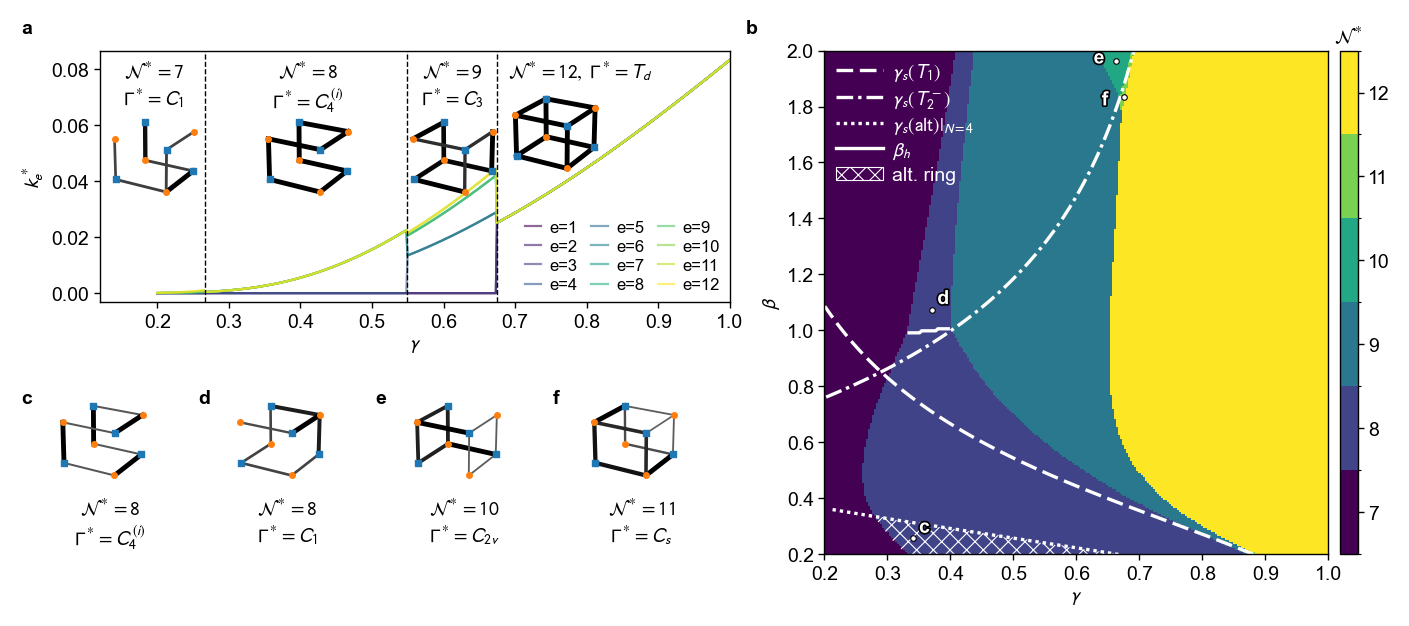

c: ring, alternating, gamma=0.34, beta=0.26
d: kite, gamma=0.37, beta=1.07
e: ten edges, gamma=0.66, beta=1.96
f: eleven edges, gamma=0.68, beta=1.83


In [7]:
node_perm, edge_perm = symmetry_group(G)

fig, gallery = plot_figure_cube(fine_results, labels, phase_names, cuts[BETA_A], G, pos,
                                node_perm, edge_perm, savepath="Figure4.pdf")
plt.show()

for letter, name, g, b in gallery:          # for the caption
    print(f"{letter}: {name}, gamma={g:.2f}, beta={b:.2f}")